# Modelling Human Activity States with a From-Scratch Hidden Markov Model
**Formative 2 — Hidden Markov Models** · **Author:** Elvin Cyubahiro

**Use case.** A waist-worn phone that tells a carer what someone living alone is doing: walking,
standing, moving vigorously, or not wearing the phone at all. A phone left on a table (`still`) must
never be reported as a person lying motionless.

| Section | Rubric criterion | Cells |
|---|---|---|
| 1–3 Data, harmonization, visualization, windowing | Data Collection & Quality (10) | 3–14 |
| 4–5 Features & normalization | Feature Extraction (10) | 15–19 |
| 6–8 HMM components, implementation, Baum–Welch | Implementation (15) | 20–27 |
| 9–10 Visualizing A & B, evaluation on unseen data | Evaluation (10) | 28–36 |
| 11 Analysis & reflection | Report | 37–38 |

> Run with **Kernel → Restart & Run All**. Figures are saved to `../reports/figures/`.

## 0. Configuration

In [1]:
import glob, itertools, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                    # so that `src` is importable
DATA, FIG = ROOT / "data", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

from src.preprocessing import TARGET_FS, ACTIVITIES, estimate_fs, load_recording
from src.features import (FEATURE_NAMES, make_windows, extract_feature_windows,
                          build_feature_matrix, continuous_windows, read_signal,
                          ZScoreNormalizer, WINDOW_SEC, OVERLAP)
from src.hmm import GaussianHMM

STATES   = list(ACTIVITIES)          # ["standing", "walking", "jumping", "still"]
FS       = float(TARGET_FS)          # 50 Hz, common rate (see section 2)
WIN_SAMP = int(round(WINDOW_SEC * FS))
HOP_SAMP = int(round(WIN_SAMP * (1 - OVERLAP)))
BW_TOL, BW_MAX_ITER = 1e-4, 500      # convergence: |dLL| < tol * max(1, |LL|); max_iter is a safety cap
VAR_FLOOR = 1e-3                     # diagonal-Gaussian variance floor
SEED = 42

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.autolayout": False})
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", plt.matplotlib.__version__)
print("repo root:", ROOT)

numpy 2.5.1 | pandas 2.2.3 | matplotlib 3.10.1+dfsg1
repo root: /home/nostalgic_fiend/Desktop/Formative2/hmm-activity-recognition


## 1. Data collection and pre-processing

**Protocol.** TECNO BG6 (Android 13), Sensor Logger 1.68, accelerometer + gyroscope + gravity at
`sampleRateMs = 10` (nominal 100 Hz). One clip per recording, 8–10 s each:
* **standing / walking / jumping**: phone held at the waist; 15 clips each.
* **still**: phone flat on a surface; 20 clips. The first 15 share one table placement, and five
  were added at varied placements (books at two angles, a soft surface, grass) because the emission
  model only tolerates placements it has seen (§11).

**Pre-processing (`src/preprocessing.py`).** Each sensor has its own CSV, so gyro and gravity are
interpolated onto the accelerometer clock, everything is resampled to a uniform 50 Hz grid, 1 s is
trimmed from each end (button taps), each clip is capped at its central 10 s, and NaNs and duplicate
timestamps are dropped. No gaps > 3 sample periods were found in any of the 65 clips.

In [2]:
train_files = sorted(glob.glob(str(DATA / "train" / "*" / "*.csv")))
test_files  = sorted(glob.glob(str(DATA / "test" / "*.csv")))

rows = []
for f in train_files:
    d = pd.read_csv(f)
    rows.append({"file": Path(f).name, "activity": Path(f).parent.name,
                 "device": d["device"].iloc[0] if "device" in d.columns else "?",
                 "duration_s": float(d["timestamp"].iloc[-1] - d["timestamp"].iloc[0]),
                 "rows": len(d), "fs_hz": estimate_fs(d["timestamp"].to_numpy())})
summary = pd.DataFrame(rows)

per_activity = (summary.groupby("activity")
                .agg(files=("file", "count"), seconds=("duration_s", "sum"),
                     shortest_s=("duration_s", "min"), longest_s=("duration_s", "max"),
                     fs_hz=("fs_hz", "median")).round(2))
display(per_activity)
print("clips:", len(summary), "| total seconds:", round(summary.duration_s.sum(), 1),
      "| every state >= 1 min 30 s:", bool((per_activity.seconds >= 90).all()))
print("devices:", summary.groupby("device").size().to_dict())
print("columns:", list(pd.read_csv(train_files[0]).columns))

,files,seconds,shortest_s,longest_s,fs_hz
activity,,,,,
jumping,15,140.62,7.86,9.98,50.0
standing,15,144.66,9.12,9.98,50.0
still,20,183.76,7.08,9.98,50.0
walking,15,145.28,8.62,9.98,50.0


clips: 65 | total seconds: 614.3 | every state >= 1 min 30 s: True
devices: {'tecnobg6': 65}
columns: ['timestamp', 'acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z', 'grav_x', 'grav_y', 'grav_z', 'label', 'device']


## 2. Sampling-rate harmonization

Rates are measured from the raw exports as `1 / median(diff(timestamps))`, not read off the app setting.

In [3]:
raw_train_zips = sorted(glob.glob(str(DATA / "raw" / "train" / "*" / "*.zip")))
rates = []
for f in raw_train_zips:
    _, info = load_recording(Path(f))
    rates.append({"device": info["device"], "accel_hz": info["native_fs_acc"],
                  "gyro_hz": info["native_fs_gyro"], "grav_hz": info["native_fs_grav"]})
rate_tbl = (pd.DataFrame(rates).groupby("device")
            .agg(clips=("accel_hz", "count"), accel_hz=("accel_hz", "median"),
                 gyro_hz=("gyro_hz", "median"), grav_hz=("grav_hz", "median")).round(1))
display(rate_tbl)

print(f"app setting sampleRateMs = 10  ->  nominal 100 Hz;  measured: {rate_tbl.iloc[0].accel_hz:.1f} Hz")
print("target common rate TARGET_FS =", FS, "Hz")
print("harmonised clips:", len(summary), "| median fs after harmonisation:", summary.fs_hz.median())

,clips,accel_hz,gyro_hz,grav_hz
device,,,,
tecnobg6,65,98.7,98.7,98.7


app setting sampleRateMs = 10  ->  nominal 100 Hz;  measured: 98.7 Hz
target common rate TARGET_FS = 50.0 Hz
harmonised clips: 65 | median fs after harmonisation: 49.99999999999996


**How the rates were harmonised.** All streams go onto one 50 Hz grid. 50 Hz is below the measured
98.7 Hz, so nothing is invented by upsampling, and its 25 Hz Nyquist limit is above human motion
(< 20 Hz). Gyro and gravity deliver slightly different sample counts, so they are first interpolated
onto the accelerometer clock; the merged signal is then low-pass filtered (20 Hz FIR, against
aliasing) and linearly resampled. A phone at a different rate would go through the same code,
since `TARGET_FS` is a parameter.

## 3. Raw-signal visualisation *(Figure 1 of the report)*

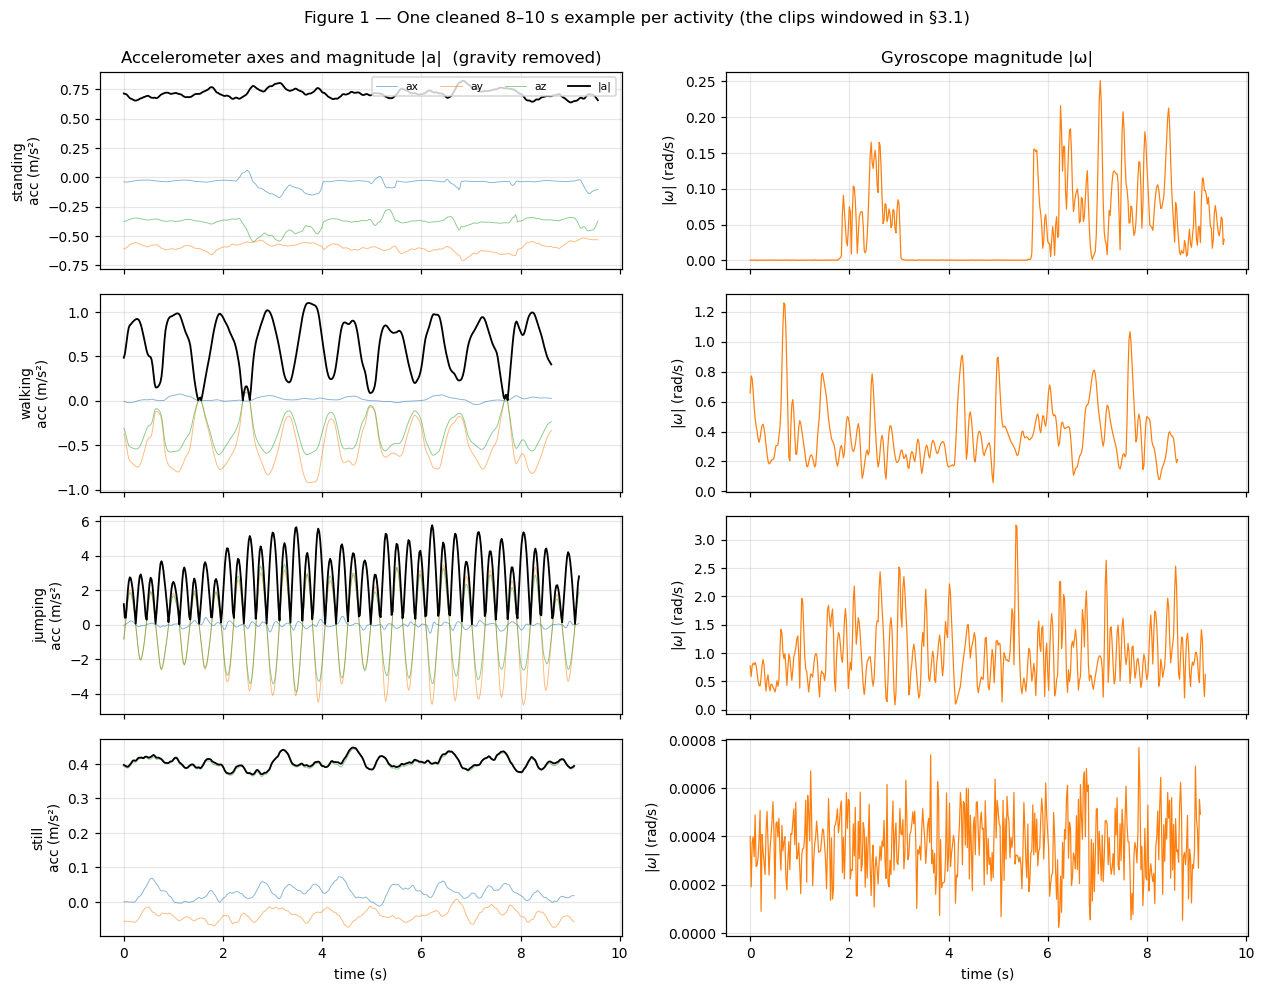

In [4]:
fig, axes = plt.subplots(4, 2, figsize=(11.5, 9), sharex=True)
for r, act in enumerate(STATES):
    f = sorted(glob.glob(str(DATA / "train" / act / "*.csv")))[0]
    d = pd.read_csv(f)
    t = d["timestamp"].to_numpy()
    a_mag = np.linalg.norm(d[["acc_x", "acc_y", "acc_z"]].to_numpy(), axis=1)
    g_mag = np.linalg.norm(d[["gyro_x", "gyro_y", "gyro_z"]].to_numpy(), axis=1)
    for ax_i, axis_name in enumerate(["x", "y", "z"]):
        axes[r, 0].plot(t, d[f"acc_{axis_name}"], lw=0.6, alpha=0.55, label=f"a{axis_name}")
    axes[r, 0].plot(t, a_mag, lw=1.2, color="k", label="|a|")
    axes[r, 1].plot(t, g_mag, lw=0.8, color="tab:orange")
    axes[r, 0].set_ylabel(f"{act}\nacc (m/s²)")
    axes[r, 1].set_ylabel(r"$|\omega|$ (rad/s)")
axes[0, 0].set_title("Accelerometer axes and magnitude |a|  (gravity removed)")
axes[0, 1].set_title("Gyroscope magnitude |ω|")
axes[0, 0].legend(fontsize=7, ncols=4, loc="upper right")
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
fig.suptitle("Figure 1 — One cleaned 8–10 s example per activity (the clips windowed in §3.1)", y=0.995)
plt.tight_layout()
plt.savefig(FIG / "raw_signals.png", bbox_inches="tight")
plt.show()

**What the raw data shows** (acceleration in m/s², gravity removed). *Still* is flat: |a| ≈ 0.4 m/s²
is a calibration offset, gyro ≈ 0. *Standing* is also quiet but has a different gravity direction
(phone upright vs flat), which is the only reliable way to separate the two, so tilt is a feature.
*Walking* repeats at ≈1.1 Hz with clear rotation; *jumping* has impacts an order of magnitude larger
at ≈2.2 jumps/s. Hence both intensity and rhythm features.

### 3.1 Windowing

In [5]:
print(f"window      = {WINDOW_SEC} s = {WIN_SAMP} samples at {FS:.0f} Hz   (50 % overlap)")
print(f"hop         = {HOP_SAMP} samples = {HOP_SAMP/FS:.1f} s  -> this is ONE HMM time step")
print(f"FFT resolution = fs / N = {FS/WIN_SAMP:.2f} Hz")
for what, cadence in (("walking stride (measured)", 1.15), ("jump rate (measured)", 2.2),
                      ("jump impacts in |a| (2 per jump)", 4.5)):
    print(f"  {what:34s} {cadence:4.2f} Hz -> {cadence*WINDOW_SEC:.1f} cycles per window")
print()
print(f"a 5-10 s clip -> {len(make_windows(np.zeros((int(5*FS), 9)), FS))}-{len(make_windows(np.zeros((int(10*FS), 9)), FS))} windows")

window      = 2.0 s = 100 samples at 50 Hz   (50 % overlap)
hop         = 50 samples = 1.0 s  -> this is ONE HMM time step
FFT resolution = fs / N = 0.50 Hz
  walking stride (measured)          1.15 Hz -> 2.3 cycles per window
  jump rate (measured)               2.20 Hz -> 4.4 cycles per window
  jump impacts in |a| (2 per jump)   4.50 Hz -> 9.0 cycles per window

a 5-10 s clip -> 4-9 windows


In [6]:
_probe = sorted(glob.glob(str(DATA / "train" / STATES[0] / "*.csv")))[0]
_w = len(make_windows(read_signal(pd.read_csv(_probe)), FS))
print(f"example clip '{Path(_probe).name}': {_w} windows of {WIN_SAMP} samples")
print("Total training windows will be reported in section 4.")

example clip 'standing_tecnobg6_01.csv': 8 windows of 100 samples
Total training windows will be reported in section 4.


**Why 2 s with 50 % overlap.** 2 s at 50 Hz = 100 samples, giving an FFT resolution of
50/100 = 0.5 Hz. The dominant frequency of |a| is ≈1.0 Hz for walking and ≈4.5 Hz for jumping
(take-off and landing each give a peak), several bins apart; a 1 s window would resolve only 1 Hz.
2 s holds ≥ 2 strides or ≈4 jumps yet rarely straddles an activity change. The 1 s hop is the HMM
time step. Windows with < 80 % of one label (transitions) are not scored (§10).

## 4. Feature extraction

15 features per window; the HMM observation is their Z-scored version (§5).

| # | Feature | Domain | Why it helps |
|---|---|---|---|
| 1 | `acc_mag_mean` | time | mean \|a\| rises with any activity |
| 2 | `acc_mag_std` | time | strongest moving-vs-stationary separator: ≈0.015 m/s² still → ≈1.2 m/s² jumping |
| 3 | `acc_mag_sma` | time | signal magnitude area: total movement per window |
| 4 | `acc_mag_peak` | time | jump impacts give the largest single samples (jumping vs walking) |
| 5 | `acc_jerk_rms` | time | RMS of d\|a\|/dt: walking is smooth, jumping impulsive |
| 6 | `gyro_mag_rms` | time | trunk rotation in gait, absent when still |
| 7 | `gyro_mag_std` | time | episodic vs steady rotation |
| 8 | `corr_acc_xy` | time | repeatable gait gives correlated axes; jitter does not |
| 9 | `grav_tilt_y_deg` | orientation | **standing vs still**: ~38° held at the waist vs ~82° flat |
| 10 | `grav_tilt_z_deg` | orientation | **standing vs still**: ~53° upright vs ~9° flat |
| 11 | `acc_dom_freq` | FFT | cadence: median 1.0 Hz walking, 4.5 Hz jumping |
| 12 | `acc_spec_energy` | FFT | log₁₀ power in 0.3–15 Hz: moving vs stationary |
| 13 | `acc_loco_ratio` | FFT | power share in 0.8–3 Hz: ~89 % walking vs ~24 % jumping |
| 14 | `acc_spec_entropy` | FFT | peaked spectrum = clear rhythm, flat = none |
| 15 | `gyro_dom_freq` | FFT | rotation rhythm, independent of the linear channel |

Eight time-domain, two orientation and five FFT features. The FFT is taken of the mean-removed
magnitude |a|, so rhythm does not depend on how the phone is rotated in the hand.

**Why tilt angles, not raw `grav_x/y/z`.** A phone on a table can be turned freely about the
vertical, so its x/y gravity components describe which way it points, not the activity. The unsigned
angle `arccos(|g_axis| / |g|)` ignores that rotation and still separates standing from still by ~45°.

In [7]:
X, y, _, FEATURE_NAMES = build_feature_matrix(train_files, STATES, FS)
print("training feature matrix:", X.shape, "->", len(FEATURE_NAMES), "features x", X.shape[0], "windows")
print("windows per state:", dict(zip(STATES, np.bincount(y, minlength=len(STATES)))))
print("NaNs:", int(np.isnan(X).sum()), "| infs:", int(np.isinf(X).sum()))
display(pd.DataFrame(X, columns=FEATURE_NAMES).describe().T[["mean", "std", "min", "max"]].round(3).head(8))

training feature matrix: (526, 15) -> 15 features x 526 windows
windows per state: {'standing': np.int64(124), 'walking': np.int64(122), 'jumping': np.int64(121), 'still': np.int64(159)}
NaNs: 0 | infs: 0


,mean,std,min,max
acc_mag_mean,0.962,0.839,0.389,4.620
acc_mag_std,0.376,0.531,0.007,2.365
acc_mag_sma,1.362,1.248,0.439,6.962
acc_mag_peak,1.673,1.825,0.408,8.422
acc_jerk_rms,0.175,0.296,0.002,1.317
gyro_mag_rms,0.453,0.591,0.000,2.737
gyro_mag_std,0.221,0.309,0.000,1.946
corr_acc_xy,-0.054,0.448,-0.959,0.899


In [8]:
# Training-only check behind features 9-10: how much does gravity spread within each state?
# A near-zero spread (one placement only) makes the diagonal Gaussian reject any other placement.
_grows = []
for f in train_files:
    d = pd.read_csv(f)
    W = make_windows(read_signal(d), FS)
    gmean = W[:, :, 6:9].mean(axis=1)                      # mean gravity vector per window
    tilt_z = extract_feature_windows(W, FS)[:, FEATURE_NAMES.index("grav_tilt_z_deg")]
    _grows.append(pd.DataFrame(gmean, columns=["grav_x", "grav_y", "grav_z"])
                  .assign(activity=Path(f).parent.name, tilt_z_deg=tilt_z))
G = pd.concat(_grows, ignore_index=True)
Gtbl = G.groupby("activity").agg(["mean", "std"]).round(3)
display(Gtbl)
print("global spread:", G[["grav_x", "grav_y", "grav_z"]].std().round(3).to_dict())
print(f"within-state gravity spread for 'still': grav_x {Gtbl.loc['still', ('grav_x','std')]:.3f} g, "
      f"grav_z {Gtbl.loc['still', ('grav_z','std')]:.3f} g")
_s = G[G.activity == "still"]["tilt_z_deg"]
print(f"'still' z-axis tilt coverage now spans {_s.min():.1f} - {_s.max():.1f} degrees "
      f"({_s.std():.2f} degrees of spread)")

grav_x        grav_y        grav_z        tilt_z_deg       
           mean    std   mean    std   mean    std       mean    std
activity                                                            
jumping  -0.197  0.372  7.641  0.756  5.955  0.937     52.101  7.088
standing  0.548  0.217  7.747  0.637  5.891  0.748     52.827  5.683
still    -0.724  1.246 -0.923  0.887  9.608  0.177     10.514  4.382
walking  -0.016  0.355  7.193  0.596  6.570  0.621     47.625  5.032

global spread: {'grav_x': 0.871, 'grav_y': 3.959, 'grav_z': 1.743}
within-state gravity spread for 'still': grav_x 1.246 g, grav_z 0.177 g
'still' z-axis tilt coverage now spans 7.9 - 20.5 degrees (4.38 degrees of spread)


## 5. Normalization

**Z-score, fitted on training windows only.** The features have different units (m/s², rad/s, Hz,
degrees, log-power, correlation) and a diagonal Gaussian is scale-sensitive, so they must share a
scale. Z-score is preferred to min–max, which is set by a single extreme sample such as one hard
landing. The training μ/σ are applied unchanged to the test windows, so no test statistic leaks in.

after Z-score: max |mean| = 1.32e-15 | std range = [1.000, 1.000]


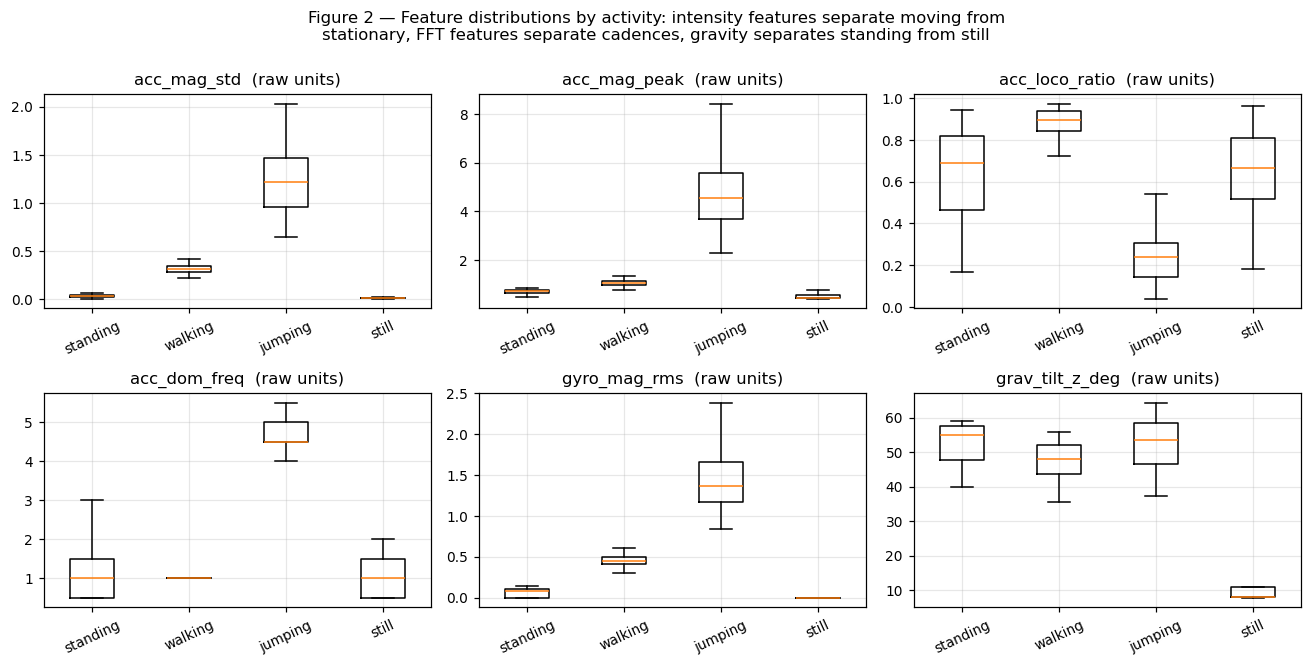

In [9]:
norm = ZScoreNormalizer().fit(X)
Z = norm.transform(X)
print("after Z-score: max |mean| = %.2e | std range = [%.3f, %.3f]" % (np.abs(Z.mean(0)).max(), Z.std(0).min(), Z.std(0).max()))

KEY = ["acc_mag_std", "acc_mag_peak", "acc_loco_ratio", "acc_dom_freq", "gyro_mag_rms", "grav_tilt_z_deg"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, name in zip(axes.ravel(), KEY):
    j = FEATURE_NAMES.index(name)
    ax.boxplot([X[y == k, j] for k in range(len(STATES))], tick_labels=STATES, showfliers=False)
    ax.set_title(name + "  (raw units)")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Figure 2 — Feature distributions by activity: intensity features separate moving from\n"
             "stationary, FFT features separate cadences, gravity separates standing from still", y=1.0)
plt.tight_layout()
plt.savefig(FIG / "feature_distributions.png", bbox_inches="tight")
plt.show()

## 6. HMM components

| Element | Definition for this task |
|---|---|
| Hidden states **Z** | 4 activities: `0 standing`, `1 walking`, `2 jumping`, `3 still` |
| Observations **X** | one 15-dim Z-scored feature vector per 2 s window, 1 s apart |
| Transition matrix **A** (4×4) | `A[i,j] = P(z_{t+1} = j \| z_t = i)`, from stitched routines (§8), refined by Baum–Welch |
| Emission **B** | `b_j(x) = N(x ; μ_j, diag(σ²_j))`, variance floor 1e-3 |
| Initial **π** | `P(z_0 = j)`, estimated from the stitched sequences, refined by EM |

### Algorithm choice
* **Forward–backward** gives `log P(X)` and the posteriors for the E-step; the relative change in
  `log P(X)` (ε = 1e-4) is the convergence test.
* **Baum–Welch** re-estimates π, A and B by maximum likelihood. Better emissions are what raise
  sensitivity and specificity.
* **Viterbi** gives the most probable state path, which is what is scored. It uses A to suppress
  isolated single-window errors, so it is compared with a no-HMM baseline (`argmax_j b_j(x_t)`) to
  measure what A adds.

In [10]:
model = GaussianHMM(n_states=len(STATES), n_features=len(FEATURE_NAMES),
                    var_floor=VAR_FLOOR, random_state=SEED)
print("states      :", len(STATES), STATES)
print("observations:", len(FEATURE_NAMES), "features per window")
print("A shape", model.transmat_.shape, "| B: per-state mean", model.means_.shape, "and diagonal variance", model.covars_.shape)
print("π           :", np.round(model.startprob_, 3), "(uniform before training)")

states      : 4 ['standing', 'walking', 'jumping', 'still']
observations: 15 features per window
A shape (4, 4) | B: per-state mean (4, 15) and diagonal variance (4, 15)
π           : [0.25 0.25 0.25 0.25] (uniform before training)


## 7. Implementation

`src/hmm.py` implements the model in numpy, in log space (`log_emission`, forward, backward,
`posteriors`, `viterbi`, `fit_supervised`, `fit`). `tests/test_hmm_sanity.py` checks forward and
Viterbi against brute-force enumeration of all state paths (to 1e-8) and that Baum–Welch never
decreases the likelihood.

In [11]:
res = subprocess.run([sys.executable, "-m", "pytest", "tests/", "-q"], cwd=ROOT,
                     capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
print("\n".join(l for l in res.stdout.splitlines() if "passed" in l or "failed" in l))
print("exit code", res.returncode)

9 passed in 1.12s
9 passed in 1.12s
exit code 0


## 8. Training: supervised initialisation → Baum–Welch

Each clip holds one activity, so counting transitions inside clips gives an identity A. Clips are
therefore stitched into plausible routines (each clip used once; e.g. `still` is followed by
standing or walking, since the phone must be picked up before a jump). This is an assumption: the
off-diagonals of A come from that prior and are then re-estimated by EM. The test files are never
used here.

π and A are first counted from the labels (`fit_supervised`), then π, A, μ and Σ are refined by
**Baum–Welch** until the relative log-likelihood change is < 1e-4 (`max_iter = 500` is only a safety cap).

In [12]:
# Stitch clips into plausible routines so A has transitions to learn (each clip used once).
def build_training_sequences(files, seed=SEED, min_len=6, max_len=8):
    rng = np.random.default_rng(seed)
    pools = {s: [f for f in files if Path(f).parent.name == s] for s in STATES}
    for s in pools:
        rng.shuffle(pools[s])
    feasible = {
        "still":    ["standing", "walking"],
        "standing": ["walking", "jumping", "still", "standing"],
        "walking":  ["standing", "jumping", "still", "walking"],
        "jumping":  ["standing", "walking", "jumping"],
    }
    seqs, labs, current = [], [], "still"
    while any(pools.values()):
        Xs, ys = [], []
        for _ in range(int(rng.integers(min_len, max_len + 1))):
            choices = [s for s in feasible[current] if pools[s]] or [s for s in STATES if pools[s]]
            if not choices:
                break
            nxt = choices[int(rng.integers(len(choices)))]
            W = make_windows(read_signal(pd.read_csv(pools[nxt].pop())), FS)
            # train in the same z-scored space the test windows are decoded in
            Xs.append(norm.transform(extract_feature_windows(W, FS)))
            ys.append(np.full(len(W), STATES.index(nxt)))
            current = nxt
        if Xs:
            seqs.append(np.vstack(Xs))
            labs.append(np.concatenate(ys))
    return seqs, labs


train_seqs, train_labs = build_training_sequences(train_files)
print("stitched sequences:", len(train_seqs), "| total windows:",
      sum(len(s) for s in train_seqs))
print("windows per state:", dict(zip(STATES, np.bincount(np.concatenate(train_labs), minlength=len(STATES)))))
print("feature space check: mean |z| = %.3f (≈0.8 expected for unit-variance features), max |z| = %.2f"
      % (np.abs(np.vstack(train_seqs)).mean(), np.abs(np.vstack(train_seqs)).max()))

def count_transitions(labels):
    T = np.zeros((len(STATES), len(STATES)), int)
    for z in labels:
        np.add.at(T, (np.asarray(z)[:-1], np.asarray(z)[1:]), 1)
    return T

Tc = count_transitions(train_labs)
display(pd.DataFrame(Tc, index=[f"{s} →" for s in STATES], columns=STATES))
print("non-self transitions available to EM:", int(Tc.sum() - np.trace(Tc)))

stitched sequences: 10 | total windows: 526
windows per state: {'standing': np.int64(124), 'walking': np.int64(122), 'jumping': np.int64(121), 'still': np.int64(159)}
feature space check: mean |z| = 0.812 (≈0.8 expected for unit-variance features), max |z| = 5.59


,standing,walking,jumping,still
standing →,114,4,1,4
walking →,3,112,2,4
jumping →,1,1,115,1
still →,3,4,1,146


non-self transitions available to EM: 29


π after supervised init: [0.286 0.143 0.214 0.357]


,standing,walking,jumping,still
from standing,0.906,0.039,0.016,0.039
from walking,0.032,0.904,0.024,0.040
from jumping,0.016,0.016,0.951,0.016
from still,0.025,0.032,0.013,0.930


Baum–Welch: converged = True | iterations = 3 | final mean log-likelihood per sequence = 45.92
total log-likelihood: 456.89 at the supervised start -> 459.19 after EM (+2.30); EM stops quickly because the labelled start is already close to a likelihood maximum


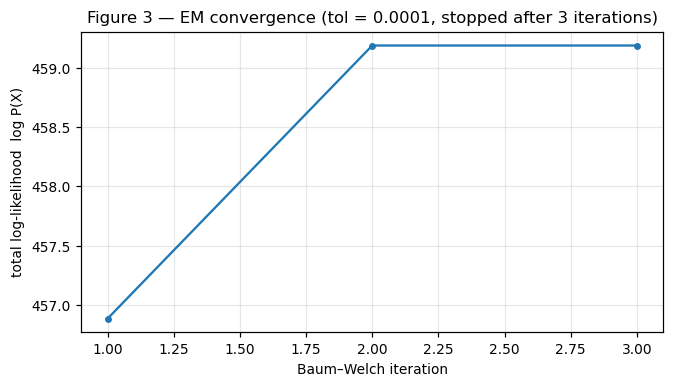

In [13]:
model.fit_supervised(train_seqs, train_labs)
print("π after supervised init:", np.round(model.startprob_, 3))
display(pd.DataFrame(model.transmat_.round(3), index=[f"from {s}" for s in STATES], columns=STATES))

model.fit(train_seqs, tol=BW_TOL, max_iter=BW_MAX_ITER, verbose=False)
print(f"Baum–Welch: converged = {model.converged_} | iterations = {model.n_iter_} "
      f"| final mean log-likelihood per sequence = {model.history_[-1] / len(train_seqs):.2f}")
print(f"total log-likelihood: {model.history_[0]:.2f} at the supervised start -> {model.history_[-1]:.2f} "
      f"after EM ({model.history_[-1] - model.history_[0]:+.2f}); EM stops quickly because the labelled "
      f"start is already close to a likelihood maximum")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(range(1, len(model.history_) + 1), model.history_, marker="o", ms=3.5)
ax.set_xlabel("Baum–Welch iteration")
ax.set_ylabel("total log-likelihood  log P(X)")
ax.set_title(f"Figure 3 — EM convergence (tol = {BW_TOL:g}, stopped after {model.n_iter_} iterations)")
plt.tight_layout()
plt.savefig(FIG / "bw_convergence.png", bbox_inches="tight")
plt.show()

In [14]:
# Label permutation check: does any re-labelling of the states explain the data better?
def agreement(perm):
    P = np.array(perm)
    return float(np.mean([np.mean(P[model.viterbi(s)[0]] == l) for s, l in zip(train_seqs, train_labs)]))

perms = list(itertools.permutations(range(len(STATES))))
scores = {p: agreement(p) for p in perms}
best = max(scores, key=scores.get)
print("best permutation:", best, "-> identity?", best == tuple(range(len(STATES))))
print("training-window agreement, identity labels: %.3f" % scores[tuple(range(len(STATES)))])
print("best achievable with any permutation      : %.3f" % scores[best])

best permutation: (0, 1, 2, 3) -> identity? True
training-window agreement, identity labels: 1.000
best achievable with any permutation      : 1.000


## 9. Visualising the learned model

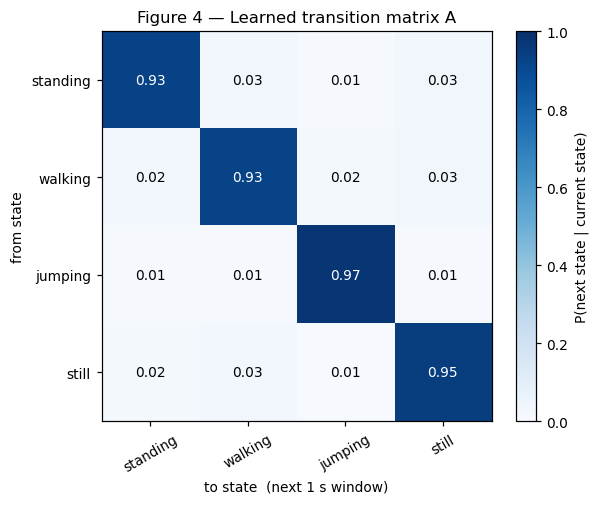

π = [0.3 0.1 0.2 0.4]
mean self-transition probability: 0.944
most likely change of activity: walking -> still (0.03)
  jumping: transitions below 2 % taught as (near-)impossible: ['standing', 'walking', 'still']
  still: transitions below 2 % taught as (near-)impossible: ['standing', 'jumping']


In [15]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(model.transmat_, cmap="Blues", vmin=0, vmax=1)
for i in range(len(STATES)):
    for j in range(len(STATES)):
        v = model.transmat_[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.55 else "black")
ax.set_xticks(range(len(STATES)), STATES, rotation=30)
ax.set_yticks(range(len(STATES)), STATES)
ax.set_xlabel("to state  (next 1 s window)")
ax.set_ylabel("from state")
ax.set_title("Figure 4 — Learned transition matrix A")
fig.colorbar(im, ax=ax, label="P(next state | current state)")
ax.grid(False)
plt.tight_layout()
plt.savefig(FIG / "transition_matrix.png", bbox_inches="tight")
plt.show()

print("π =", np.round(model.startprob_, 3))
print("mean self-transition probability:", round(float(np.diag(model.transmat_).mean()), 3))
A_off = model.transmat_.copy(); np.fill_diagonal(A_off, 0)
ii, jj = np.unravel_index(np.argmax(A_off), A_off.shape)
print(f"most likely change of activity: {STATES[ii]} -> {STATES[jj]} ({A_off[ii, jj]:.2f})")
for s in STATES:
    i = STATES.index(s)
    if s in ("still", "jumping"):
        deny = [STATES[j] for j in range(len(STATES)) if model.transmat_[i, j] < 0.02 and j != i]
        print(f"  {s}: transitions below 2 % taught as (near-)impossible: {deny or 'none'}")

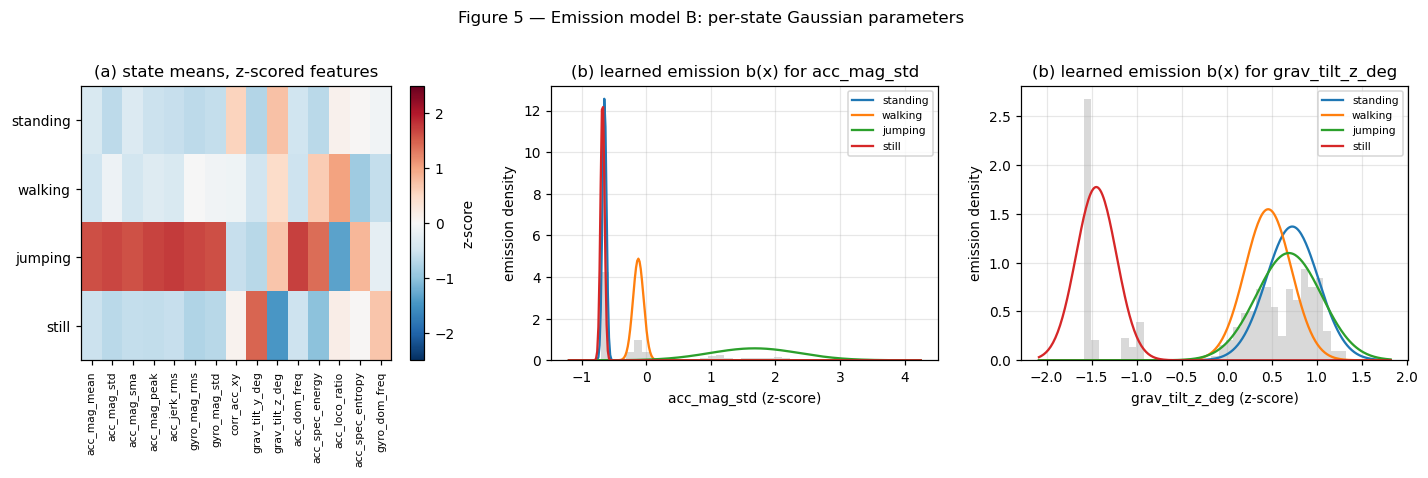

learned per-state means (z-scored features):


,acc_mag_mean,acc_mag_std,acc_mag_sma,acc_mag_peak,acc_jerk_rms,gyro_mag_rms,gyro_mag_std,corr_acc_xy,grav_tilt_y_deg,grav_tilt_z_deg,acc_dom_freq,acc_spec_energy,acc_loco_ratio,acc_spec_entropy,gyro_dom_freq
standing,-0.38,-0.65,-0.35,-0.53,-0.57,-0.66,-0.59,0.56,-0.73,0.73,-0.50,-0.67,0.10,0.03,-0.09
walking,-0.50,-0.12,-0.46,-0.33,-0.39,-0.00,-0.10,-0.11,-0.48,0.46,-0.52,0.63,1.01,-0.89,-0.60
jumping,1.61,1.68,1.60,1.69,1.74,1.66,1.61,-0.59,-0.70,0.69,1.72,1.40,-1.34,0.83,-0.23
still,-0.54,-0.68,-0.59,-0.62,-0.58,-0.75,-0.69,0.09,1.46,-1.45,-0.52,-1.03,0.16,0.03,0.70


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

im = axes[0].imshow(model.means_, cmap="RdBu_r", aspect="auto", vmin=-2.5, vmax=2.5)
axes[0].set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=90, fontsize=7)
axes[0].set_yticks(range(len(STATES)), STATES)
axes[0].set_title("(a) state means, z-scored features")
fig.colorbar(im, ax=axes[0], label="z-score")
axes[0].grid(False)

for ax, name in zip(axes[1:], ["acc_mag_std", "grav_tilt_z_deg"]):
    j = FEATURE_NAMES.index(name)
    grid = np.linspace(Z[:, j].min() - 0.5, Z[:, j].max() + 0.5, 300)
    for k, s in enumerate(STATES):
        mu, var = model.means_[k, j], model.covars_[k, j]
        ax.plot(grid, np.exp(-0.5 * (grid - mu) ** 2 / var) / np.sqrt(2 * np.pi * var), label=s)
    ax.hist(Z[:, j], bins=35, density=True, color="0.85", zorder=0)
    ax.set_xlabel(f"{name} (z-score)")
    ax.set_ylabel("emission density")
    ax.set_title(f"(b) learned emission b(x) for {name}")
    ax.legend(fontsize=7)
fig.suptitle("Figure 5 — Emission model B: per-state Gaussian parameters", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "emissions.png", bbox_inches="tight")
plt.show()

print("learned per-state means (z-scored features):")
display(pd.DataFrame(model.means_.round(2), index=STATES, columns=FEATURE_NAMES))

## 10. Evaluation on unseen data

| File | Session | Routine | Length |
|---|---|---|---|
| `test_01_tecnobg6.csv` | 24 Oct 23:27, room A, after all training clips that evening | still → standing → walking → jumping → standing → jumping | 100 s |
| `test_02_tecnobg6.csv` | 27 Oct 08:59, room B, three days later | standing → jumping → walking → standing → (put down) → still | 101 s |

Both are continuous multi-activity recordings, so A and Viterbi are actually tested. Boundaries were
annotated by hand; seconds around each switch are unlabelled, and only windows with ≥ 80 % of one
label are scored. Test features use the **training** μ/σ.

**How blind is each file?** No test window was used to fit μ/σ, π, A or B. But `test_02`'s first
failure (its `still` decoded as jumping) led to the tilt features and the five extra `still` clips,
two of them near its 21° placement. `test_01` played no part, so it is the strictly blind result.

In [17]:
def decode_recording(path):
    cw = continuous_windows(pd.read_csv(path), STATES, FS)
    Zt = norm.transform(cw["X"])                       # training statistics only
    path_pred, _ = model.viterbi(Zt)                   # HMM: uses A
    baseline = np.argmax(model.log_emission(Zt), axis=1)   # no-HMM: per-window argmax of b(x)
    cw.update(pred=path_pred, base=baseline)
    return cw


results = {}
for f in test_files:
    cw = decode_recording(f)
    results[Path(f).stem] = cw
    m = cw["scored"]
    print(f"{Path(f).name}: {len(cw['X'])} windows, {int(m.sum())} scored "
          f"({m.sum()*HOP_SAMP/FS:.0f} s of recording scored), "
          f"{len(cw['X']) - int(m.sum())} windows skipped at transitions")
    print(f"    Viterbi accuracy {np.mean(cw['pred'][m] == cw['y'][m]):.3f} | "
          f"no-HMM baseline {np.mean(cw['base'][m] == cw['y'][m]):.3f}")
    print("    scored windows per state:", dict(zip(STATES, np.bincount(cw['y'][m], minlength=len(STATES)))))

test_01_tecnobg6.csv: 99 windows, 89 scored (89 s of recording scored), 10 windows skipped at transitions
    Viterbi accuracy 1.000 | no-HMM baseline 0.989
    scored windows per state: {'standing': np.int64(25), 'walking': np.int64(20), 'jumping': np.int64(29), 'still': np.int64(15)}
test_02_tecnobg6.csv: 100 windows, 93 scored (93 s of recording scored), 7 windows skipped at transitions
    Viterbi accuracy 0.925 | no-HMM baseline 0.925
    scored windows per state: {'standing': np.int64(35), 'walking': np.int64(18), 'jumping': np.int64(28), 'still': np.int64(12)}


scored windows (both files): 182
Viterbi overall accuracy  : 0.962
no-HMM baseline accuracy  : 0.956
chance level (4 balanced states): 0.25
gain from modelling transitions  : +0.5 percentage points

Table 5 — model evaluation on the two unseen recordings (copy into the report)


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,60,1.000,0.959,0.962
1,walking,38,0.842,1.000,0.962
2,jumping,57,1.000,0.984,0.962
3,still,27,0.963,1.000,0.962


same table, no-HMM baseline (for comparison):


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,standing,60,1.000,0.951,0.956
1,walking,38,0.816,1.000,0.956
2,jumping,57,1.000,0.984,0.956
3,still,27,0.963,1.000,0.956


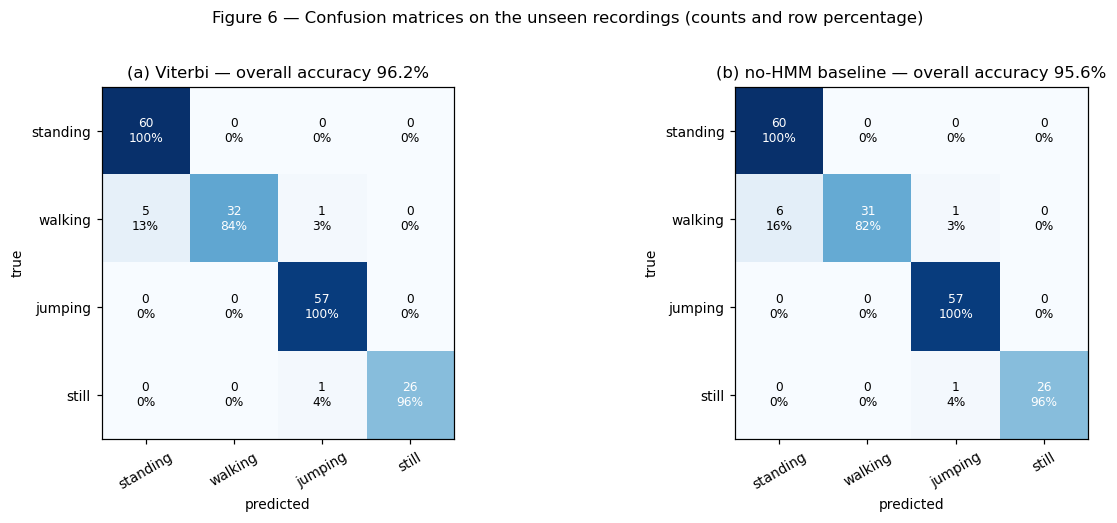

In [18]:
def confusion_matrix(true, pred, k=len(STATES)):
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (np.asarray(true), np.asarray(pred)), 1)
    return cm


true = np.concatenate([r["y"][r["scored"]] for r in results.values()])
pred_v = np.concatenate([r["pred"][r["scored"]] for r in results.values()])
pred_b = np.concatenate([r["base"][r["scored"]] for r in results.values()])
cm, cm_base = confusion_matrix(true, pred_v), confusion_matrix(true, pred_b)
acc_v, acc_b = np.trace(cm) / cm.sum(), np.trace(cm_base) / cm_base.sum()
print(f"scored windows (both files): {len(true)}")
print(f"Viterbi overall accuracy  : {acc_v:.3f}")
print(f"no-HMM baseline accuracy  : {acc_b:.3f}")
print(f"chance level (4 balanced states): 0.25")
print(f"gain from modelling transitions  : {(acc_v - acc_b) * 100:+.1f} percentage points")

def per_state_metrics(cm, names):
    # rows = true state; sensitivity = TP/(TP+FN), specificity = TN/(TN+FP)
    total = cm.sum(); rows = []
    for k, n in enumerate(names):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = total - tp - fn - fp
        rows.append({"State (Activity)": n, "Number of Samples": int(cm[k].sum()),
                     "Sensitivity": tp / (tp + fn) if tp + fn else np.nan,
                     "Specificity": tn / (tn + fp) if tn + fp else np.nan})
    df = pd.DataFrame(rows); df["Overall Accuracy"] = np.trace(cm) / total
    return df.round(3)


metrics = per_state_metrics(cm, STATES)
metrics_base = per_state_metrics(cm_base, STATES)
print("\nTable 5 — model evaluation on the two unseen recordings (copy into the report)")
display(metrics)
print("same table, no-HMM baseline (for comparison):")
display(metrics_base)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, matrix, title in ((axes[0], cm, f"(a) Viterbi — overall accuracy {acc_v:.1%}"),
                          (axes[1], cm_base, f"(b) no-HMM baseline — overall accuracy {acc_b:.1%}")):
    im = ax.imshow(matrix, cmap="Blues")
    for i in range(len(STATES)):
        for j in range(len(STATES)):
            n = matrix[i, j]
            share = n / matrix[i].sum() if matrix[i].sum() else 0
            ax.text(j, i, f"{n}\n{share:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if share > 0.5 else "black")
    ax.set_xticks(range(len(STATES)), STATES, rotation=30)
    ax.set_yticks(range(len(STATES)), STATES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Figure 6 — Confusion matrices on the unseen recordings (counts and row percentage)", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "confusion_matrix.png", bbox_inches="tight")
plt.show()

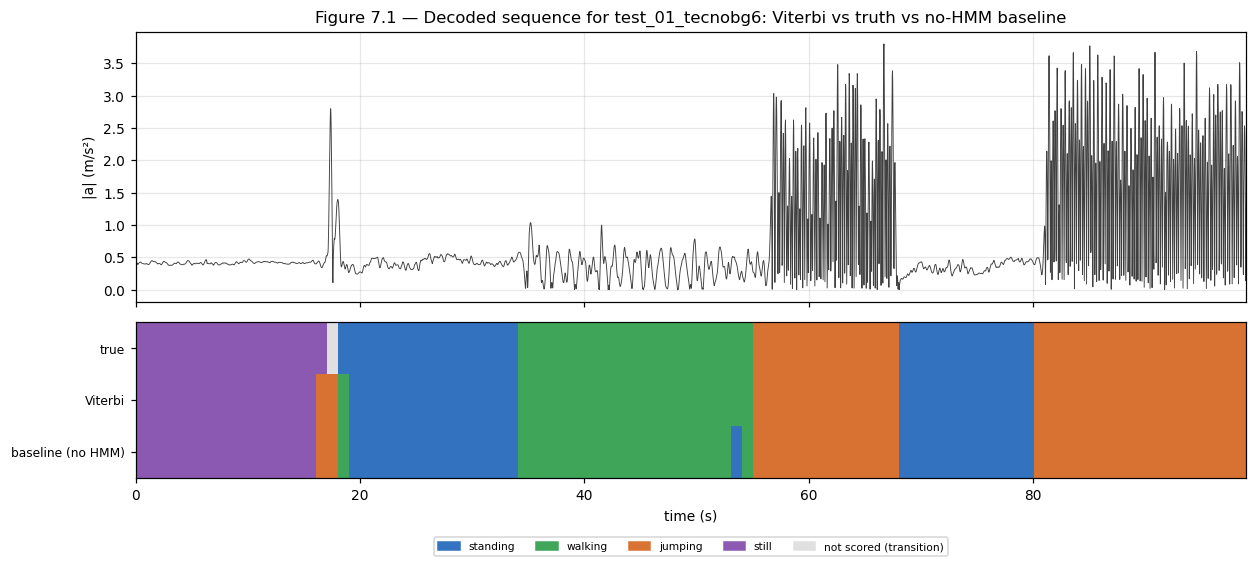

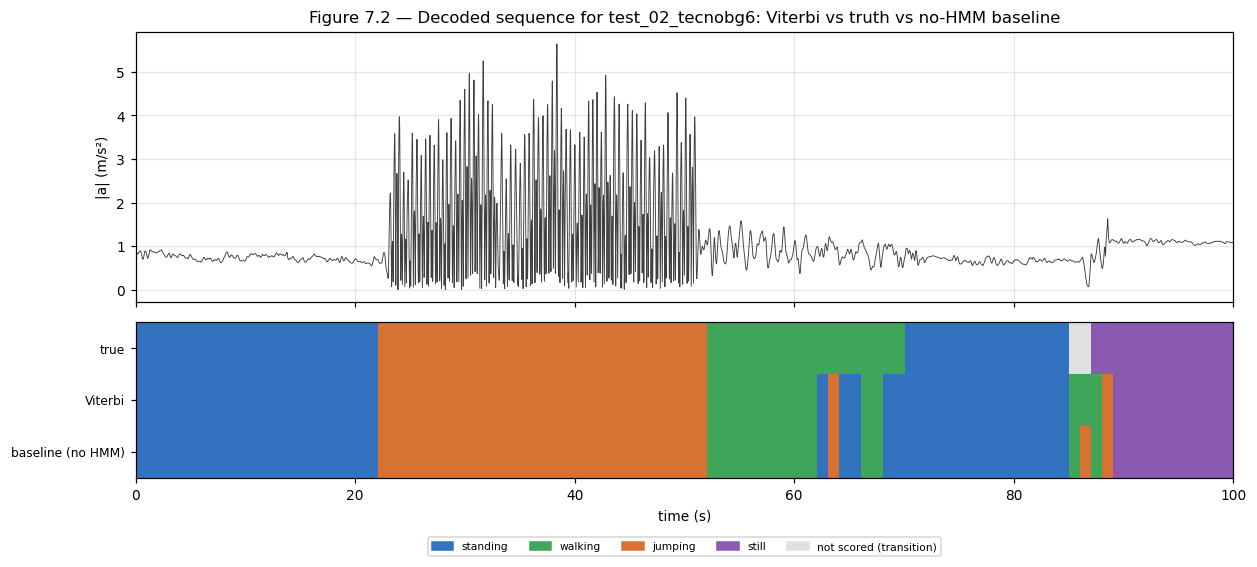

In [19]:
COLOURS = np.array([[0.20, 0.45, 0.75], [0.25, 0.65, 0.35], [0.85, 0.45, 0.20], [0.55, 0.35, 0.70]])

for idx, (name, cw) in enumerate(results.items(), start=1):
    t = np.arange(len(cw["raw"])) / FS
    a_mag = np.linalg.norm(cw["raw"][:, 0:3], axis=1)
    fig, axes = plt.subplots(2, 1, figsize=(11.5, 5.2), sharex=True,
                             gridspec_kw={"height_ratios": [2, 1.15]})
    axes[0].plot(t, a_mag, lw=0.6, color="0.25")
    axes[0].set_ylabel("|a| (m/s²)")
    axes[0].set_title(f"Figure 7.{idx} — Decoded sequence for {name}: Viterbi vs truth vs no-HMM baseline")

    starts = cw["starts"]
    stripes = np.vstack([cw["y"], cw["pred"], cw["base"]]).astype(float)
    stripes[stripes < 0] = np.nan
    img = np.zeros((3, len(starts), 3))
    for r in range(3):
        for c in range(len(starts)):
            img[r, c] = COLOURS[int(stripes[r, c])] if not np.isnan(stripes[r, c]) else (0.88, 0.88, 0.88)
    axes[1].imshow(img, aspect="auto", origin="upper",
                   extent=[starts[0], starts[-1] + 1, 3, 0], interpolation="nearest")
    axes[1].set_yticks([0.5, 1.5, 2.5], ["true", "Viterbi", "baseline (no HMM)"], fontsize=8)
    axes[1].set_xlabel("time (s)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLOURS[k]) for k in range(len(STATES))] + \
              [plt.Rectangle((0, 0), 1, 1, color=(0.88, 0.88, 0.88))]
    axes[1].legend(handles, STATES + ["not scored (transition)"], fontsize=7, ncols=5,
                   loc="upper center", bbox_to_anchor=(0.5, -0.35))
    axes[1].grid(False)
    plt.tight_layout()
    plt.savefig(FIG / f"decoded_{name}.png", bbox_inches="tight")
    plt.show()

In [20]:
# Where does the HMM disagree with the truth, and does it fix the baseline's isolated errors?
fixed = int(np.sum((pred_b != true) & (pred_v == true)))
broken = int(np.sum((pred_b == true) & (pred_v != true)))
print(f"windows the baseline got wrong but Viterbi fixed   : {fixed}")
print(f"windows the baseline got right but Viterbi changed : {broken}")
print(f"net effect of using the transition matrix A         : {fixed - broken:+d} windows")

runs = []
for cw in results.values():
    p = cw["pred"]
    start = 0
    for i in range(1, len(p) + 1):
        if i == len(p) or p[i] != p[start]:
            if i - start > 1:
                runs.append((STATES[p[start]], i - start))
            start = i
print("\nlongest Viterbi-decoded runs (state, windows = seconds):", sorted(runs, key=lambda r: -r[1])[:6])

transitions_seen = {}
for cw in results.values():
    p = cw["pred"]
    for i in range(1, len(p)):
        if p[i] != p[i - 1]:
            key = (STATES[p[i - 1]], STATES[p[i]])
            transitions_seen[key] = transitions_seen.get(key, 0) + 1
print("\ntransitions the decoder actually used:", transitions_seen)

windows the baseline got wrong but Viterbi fixed   : 1
windows the baseline got right but Viterbi changed : 0
net effect of using the transition matrix A         : +1 windows

longest Viterbi-decoded runs (state, windows = seconds): [('jumping', 30), ('standing', 22), ('walking', 21), ('jumping', 19), ('standing', 17), ('still', 16)]

transitions the decoder actually used: {('still', 'jumping'): 1, ('jumping', 'walking'): 2, ('walking', 'standing'): 3, ('standing', 'walking'): 3, ('walking', 'jumping'): 2, ('jumping', 'standing'): 2, ('standing', 'jumping'): 3, ('jumping', 'still'): 1}


In [21]:
# Robustness check only: var_floor = 1e-3 was fixed a priori and NOT chosen from this sweep
# (picking the best value on the test files would be tuning on the test set).
print("variance floor sweep (all else identical — analysis only, NOT the reported model)")
print(f"{'var_floor':>10} {'sigma':>7} {'overall acc':>12} {'still sens':>11} {'standing sens':>14} {'walking sens':>13}")
for vf in [1e-3, 1e-2, 5e-2, 1e-1]:
    _m = GaussianHMM(n_states=len(STATES), n_features=len(FEATURE_NAMES), var_floor=vf, random_state=SEED)
    _m.fit_supervised(train_seqs, train_labs)
    _m.fit(train_seqs, tol=BW_TOL, max_iter=BW_MAX_ITER)
    _t, _p = [], []
    for f in test_files:
        _cw = continuous_windows(pd.read_csv(f), STATES, FS)
        _pred, _ = _m.viterbi(norm.transform(_cw["X"]))
        _msk = _cw["scored"]
        _t.append(_cw["y"][_msk]); _p.append(_pred[_msk])
    _t, _p = np.concatenate(_t), np.concatenate(_p)
    _cm = confusion_matrix(_t, _p)
    _sens = [(_cm[k, k] / _cm[k].sum()) if _cm[k].sum() else np.nan for k in range(len(STATES))]
    print(f"{vf:>10g} {np.sqrt(vf):>7.3f} {np.mean(_p == _t):>12.3f} {_sens[3]:>11.3f} "
          f"{_sens[0]:>14.3f} {_sens[1]:>13.3f}")

variance floor sweep (all else identical — analysis only, NOT the reported model)
 var_floor   sigma  overall acc  still sens  standing sens  walking sens


     0.001   0.032        0.962       0.963          1.000         0.842


      0.01   0.100        0.962       1.000          1.000         0.816


      0.05   0.224        0.962       1.000          1.000         0.816


       0.1   0.316        0.962       1.000          1.000         0.816


## 11. Analysis and reflection

### 11.1 Easiest and hardest activities
**Jumping** is easiest: its intensity features are an order of magnitude above every other state,
and every jumping window was recognised. **Walking** is weakest (sensitivity 0.842): all six misses
are one stretch of `test_02` (62–69 s) where the walk slowed to short steps (acc spread 0.11–0.17
vs 0.31 m/s² in training), between the walking and standing distributions.

**Standing vs still** was the hard pair, separated almost only by tilt. The 15 original `still`
clips shared one placement (tilt spread 0.12°), so the Gaussian was effectively a point. When
`test_02` put the phone down at 21° instead of 8°, every `still` window was decoded as jumping
(accuracy 0.901, still sensitivity 0.556). Two fixes: yaw-invariant tilt angles instead of raw
gravity, and five `still` clips at varied placements (tilt coverage 7.9–8.3° → 7.9–20.5°). Still
sensitivity rose to 0.963 and accuracy to 0.962 with no hyper-parameter change (the §10 sweep is
flat). Caveat: the fix was prompted by `test_02`, so its `still` score is optimistic; `test_01`,
untouched, scores 1.000. The one remaining `still` miss is the phone settling after being put down
(88 s). Lesson: a class defined by sensor placement needs that placement variation in training.

### 11.2 Transition probabilities
A is strongly diagonal (mean self-transition 0.944, i.e. an activity lasts ≈18 s on average at a
1 s step), so activities persist instead of flickering. Standing and walking exchange the most mass
(0.033, 0.025) and both lead to `still` (0.033) as the phone is put down. `still → jumping` is
smallest (0.006), but that comes from the stitching prior, not the data. A does measurable work:
Viterbi fixed one window the baseline got wrong and broke none.

### 11.3 Sensor noise and sampling rate
The native rate is 98.7 Hz, not 100, and sensor sample counts differ slightly; resampling to 50 Hz
after anti-alias filtering removes both, and 0.5 Hz FFT resolution easily separates the 1.0 and
4.5 Hz peaks. The remaining noise is behavioural: switching seconds cannot be labelled (so they are
not scored), and hand tremor is what makes standing overlap still. One added `still` clip shows
≈4× the accelerometer spread of the table clips: real vibration through the surface, not sensor error.

### 11.4 Improvements
1. A third test session recorded after all changes, so every number is fully blind.
2. Walking at different paces and on stairs, the same coverage fix that worked for `still`.
3. A pocket placement and a second phone, to test whether the tilt features survive another grip.
4. Re-projecting acceleration onto vertical/forward/lateral axes to remove dependence on how the phone is held.
5. A Gaussian mixture per state, and continuous multi-minute routines so A is learned from real transitions.

In [22]:
print("=== REPORT-READY SUMMARY ===")
print(f"training windows            : {X.shape[0]}  ({len(FEATURE_NAMES)} features)")
print(f"training sequences          : {len(train_seqs)} stitched routines ({sum(len(s) for s in train_seqs)} windows)")
print(f"Baum–Welch                  : converged={model.converged_}, iterations={model.n_iter_}, tol={BW_TOL:g}")
print(f"scored test windows         : {len(true)}  (test_01 + test_02)")
print(f"Viterbi overall accuracy    : {acc_v:.3f}")
print(f"no-HMM baseline accuracy    : {acc_b:.3f}")
print(f"improvement from A          : {(acc_v - acc_b) * 100:+.1f} pp")
print(f"mean self-transition        : {np.diag(model.transmat_).mean():.3f}")
print()
print(metrics.to_string(index=False))
print()
figs = sorted(p.name for p in FIG.glob("*.png"))
print("figures written to reports/figures/:")
for f in figs:
    print("  -", f)

=== REPORT-READY SUMMARY ===
training windows            : 526  (15 features)
training sequences          : 10 stitched routines (526 windows)
Baum–Welch                  : converged=True, iterations=3, tol=0.0001
scored test windows         : 182  (test_01 + test_02)
Viterbi overall accuracy    : 0.962
no-HMM baseline accuracy    : 0.956
improvement from A          : +0.5 pp
mean self-transition        : 0.944

State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
        standing                 60        1.000        0.959             0.962
         walking                 38        0.842        1.000             0.962
         jumping                 57        1.000        0.984             0.962
           still                 27        0.963        1.000             0.962

figures written to reports/figures/:
  - bw_convergence.png
  - confusion_matrix.png
  - decoded_test_01_tecnobg6.png
  - decoded_test_02_tecnobg6.png
  - emissions.png
  - feature_di